In [160]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,roc_auc_score,roc_curve
import warnings
warnings.filterwarnings("ignore")
from sklearn.preprocessing import LabelEncoder

In [23]:
travel_i=pd.read_csv(filepath_or_buffer="insurance_part2_data (1).csv")
travel_i

,Age,Agency_Code,Type,Claimed,Commision,Channel,Duration,Sales,Product Name,Destination
0,48,C2B,Airlines,No,0.70,Online,7,2.51,Customised Plan,ASIA
1,36,EPX,Travel Agency,No,0.00,Online,34,20.00,Customised Plan,ASIA
2,39,CWT,Travel Agency,No,5.94,Online,3,9.90,Customised Plan,Americas
3,36,EPX,Travel Agency,No,0.00,Online,4,26.00,Cancellation Plan,ASIA
4,33,JZI,Airlines,No,6.30,Online,53,18.00,Bronze Plan,ASIA
...,...,...,...,...,...,...,...,...,...,...
2995,28,CWT,Travel Agency,Yes,166.53,Online,364,256.20,Gold Plan,Americas
2996,35,C2B,Airlines,No,13.50,Online,5,54.00,Gold Plan,ASIA
2997,36,EPX,Travel Agency,No,0.00,Online,54,28.00,Customised Plan,ASIA
2998,34,C2B,Airlines,Yes,7.64,Online,39,30.55,Bronze Plan,ASIA


#### DATA UNDERSTANDING:

In [3]:
travel_i.isna().sum()

Age             0
Agency_Code     0
Type            0
Claimed         0
Commision       0
Channel         0
Duration        0
Sales           0
Product Name    0
Destination     0
dtype: int64

In [4]:
travel_i.describe()

,Age,Commision,Duration,Sales
count,3000.000000,3000.000000,3000.000000,3000.000000
mean,38.091000,14.529203,70.001333,60.249913
std,10.463518,25.481455,134.053313,70.733954
min,8.000000,0.000000,-1.000000,0.000000
25%,32.000000,0.000000,11.000000,20.000000
50%,36.000000,4.630000,26.500000,33.000000
75%,42.000000,17.235000,63.000000,69.000000
max,84.000000,210.210000,4580.000000,539.000000


In [5]:
travel_i.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Age           3000 non-null   int64  
 1   Agency_Code   3000 non-null   object 
 2   Type          3000 non-null   object 
 3   Claimed       3000 non-null   object 
 4   Commision     3000 non-null   float64
 5   Channel       3000 non-null   object 
 6   Duration      3000 non-null   int64  
 7   Sales         3000 non-null   float64
 8   Product Name  3000 non-null   object 
 9   Destination   3000 non-null   object 
dtypes: float64(2), int64(2), object(6)
memory usage: 234.5+ KB


#### DATA PREPARATION:

In [6]:
travel_i['Type'].unique()

array(['Airlines', 'Travel Agency'], dtype=object)

In [7]:
travel_i['Product Name'].unique()

array(['Customised Plan', 'Cancellation Plan', 'Bronze Plan',
       'Silver Plan', 'Gold Plan'], dtype=object)

In [25]:
travel_i['Destination'].unique()

array(['ASIA', 'Americas', 'EUROPE'], dtype=object)

In [26]:
le=LabelEncoder()
travel_i['Claimed']=le.fit_transform(travel_i['Claimed'])
travel_i['Type']=le.fit_transform(travel_i['Type'])
travel_i['Product Name']=le.fit_transform(travel_i['Product Name'])
travel_i['Channel']=le.fit_transform(travel_i['Channel'])
travel_i['Destination']=le.fit_transform(travel_i['Destination'])

In [27]:
del travel_i['Agency_Code']

In [28]:
travel_i

,Age,Type,Claimed,Commision,Channel,Duration,Sales,Product Name,Destination
0,48,0,0,0.70,1,7,2.51,2,0
1,36,1,0,0.00,1,34,20.00,2,0
2,39,1,0,5.94,1,3,9.90,2,1
3,36,1,0,0.00,1,4,26.00,1,0
4,33,0,0,6.30,1,53,18.00,0,0
...,...,...,...,...,...,...,...,...,...
2995,28,1,1,166.53,1,364,256.20,3,1
2996,35,0,0,13.50,1,5,54.00,3,0
2997,36,1,0,0.00,1,54,28.00,2,0
2998,34,0,1,7.64,1,39,30.55,0,0


##### DATA SEPERATION:

In [30]:
y=travel_i['Claimed']
y

0       0
1       0
2       0
3       0
4       0
       ..
2995    1
2996    0
2997    0
2998    1
2999    0
Name: Claimed, Length: 3000, dtype: int64

In [33]:
x=travel_i.drop(labels='Claimed',axis=1)
x

,Age,Type,Commision,Channel,Duration,Sales,Product Name,Destination
0,48,0,0.70,1,7,2.51,2,0
1,36,1,0.00,1,34,20.00,2,0
2,39,1,5.94,1,3,9.90,2,1
3,36,1,0.00,1,4,26.00,1,0
4,33,0,6.30,1,53,18.00,0,0
...,...,...,...,...,...,...,...,...
2995,28,1,166.53,1,364,256.20,3,1
2996,35,0,13.50,1,5,54.00,3,0
2997,36,1,0.00,1,54,28.00,2,0
2998,34,0,7.64,1,39,30.55,0,0


#### MODEL BUILDING:

In [34]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.30,random_state=25,shuffle=True)
x_train,x_test,y_train,y_test

(      Age  Type  Commision  Channel  Duration  Sales  Product Name  \
 2495   30     0       7.70        1         4   22.0             0   
 795    30     1     166.53        1       375  256.2             3   
 1138   43     0       3.38        1         4   13.5             0   
 632    36     1       0.00        1         5   10.0             1   
 2285   34     1     166.53        1       421  256.2             3   
 ...   ...   ...        ...      ...       ...    ...           ...   
 2934   52     0       6.00        1        15   15.0             0   
 2191   28     1      17.82        1        71   29.7             2   
 2522   36     1       0.00        1        49   94.0             2   
 318    36     1       0.00        1        35   10.0             1   
 1156   79     1       0.00        1        41   78.0             2   
 
       Destination  
 2495            0  
 795             1  
 1138            0  
 632             0  
 2285            1  
 ...           ...  

In [36]:
x_train.shape,y_train.shape

((2100, 8), (2100,))

In [37]:
x_test.shape,y_test.shape

((900, 8), (900,))

#### MODEL TRAINING:

In [130]:
dt_classifier=DecisionTreeClassifier(criterion='gini',max_depth=10)
dt_classifier

,criterion,'gini'
,splitter,'best'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [153]:
rf_classifier=RandomForestClassifier(n_estimators=75,criterion='gini',max_depth=10)
rf_classifier

,n_estimators,75
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [206]:
ann=MLPClassifier(hidden_layer_sizes=(100,50),activation='relu',solver='adam',max_iter=200)
ann

,hidden_layer_sizes,"(100, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,200
,shuffle,True
,random_state,None


In [131]:
%time
dt_classifier.fit(x_train,y_train)

CPU times: total: 0 ns
Wall time: 0 ns


,criterion,'gini'
,splitter,'best'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [154]:
%time
rf_classifier.fit(x_train,y_train)

CPU times: total: 0 ns
Wall time: 0 ns


,n_estimators,75
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [207]:
%time
ann.fit(x_train,y_train)

CPU times: total: 0 ns
Wall time: 0 ns


,hidden_layer_sizes,"(100, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,200
,shuffle,True
,random_state,None


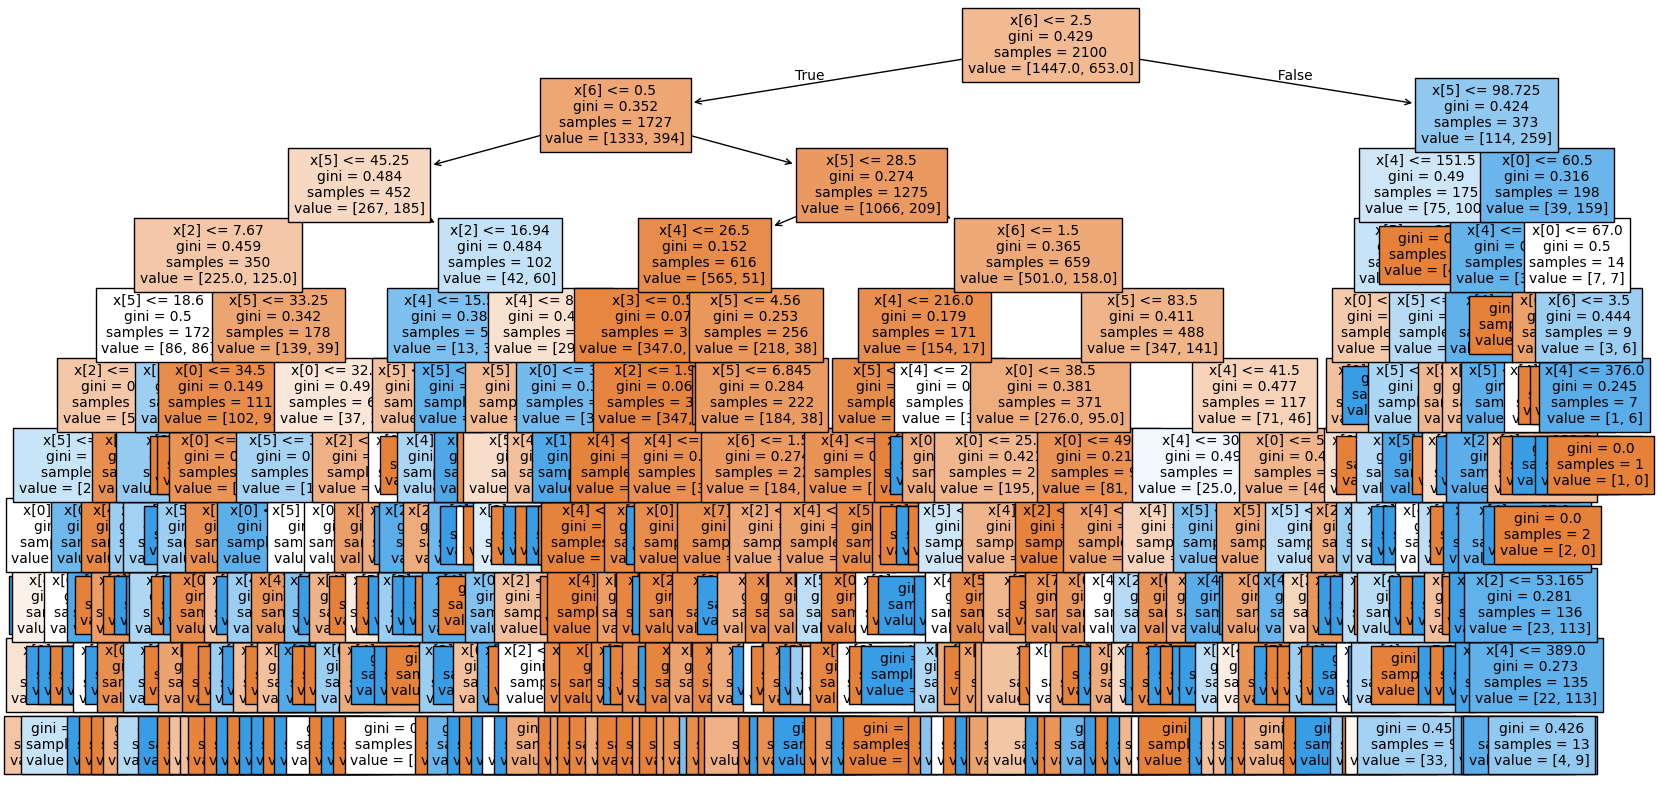

In [132]:
plt.figure(figsize=(20,10))
plot_tree(decision_tree=dt_classifier,fontsize=10,filled=True)
plt.show()

#### MODEL TESTING:

In [208]:
y_pred_dt=dt_classifier.predict(x_test)
y_pred_rf=rf_classifier.predict(x_test)
y_pred_ann=ann.predict(x_test)

#### MODEL EVALUATION:

##### RANDOMFOREST_CLASSIFIER:

In [156]:
print(classification_report(y_test,y_pred_rf))

              precision    recall  f1-score   support

           0       0.83      0.89      0.86       629
           1       0.70      0.58      0.63       271

    accuracy                           0.80       900
   macro avg       0.77      0.74      0.75       900
weighted avg       0.79      0.80      0.79       900



In [157]:
accuracy_score(y_test,y_pred_rf)

0.7988888888888889

In [158]:
print(confusion_matrix(y_test,y_pred_rf))

[[562  67]
 [114 157]]


In [159]:
roc_auc_score(y_test,y_pred_rf)

0.7364087551845311

##### DECISIONTREE_CLASSIFIER:

In [135]:
print(classification_report(y_test,y_pred_dt))

              precision    recall  f1-score   support

           0       0.82      0.82      0.82       629
           1       0.58      0.59      0.59       271

    accuracy                           0.75       900
   macro avg       0.70      0.71      0.70       900
weighted avg       0.75      0.75      0.75       900



In [136]:
accuracy_score(y_test,y_pred_dt)

0.75

In [137]:
print(confusion_matrix(y_test,y_pred_dt))

[[514 115]
 [110 161]]


In [138]:
roc_auc_score(y_test,y_pred_dt)

0.7056330261235839

##### ARTIFICIAL NERUAL NETWORK:

In [209]:
print(classification_report(y_test,y_pred_ann))

              precision    recall  f1-score   support

           0       0.81      0.88      0.85       629
           1       0.66      0.53      0.59       271

    accuracy                           0.78       900
   macro avg       0.74      0.71      0.72       900
weighted avg       0.77      0.78      0.77       900



In [210]:
accuracy_score(y_test,y_pred_ann)

0.7755555555555556

In [211]:
print(confusion_matrix(y_test,y_pred_ann))

[[555  74]
 [128 143]]


In [212]:
roc_auc_score(y_test,y_pred_ann)

0.705014108964619

===========================================================================================================================================